# Simple regression example: height and weight

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Data from Howell, N. (census of the Dobe area !Kung San, 1960s), as used in McElreath, R. (2020) Statistical Rethinking. CRC Press.

Each row is a person, with the height (cm), weight (kg), age (years) and sex.

In [2]:
dat_all = pd.read_csv('howell1.csv', sep=';')
dat_all.head()

,height,weight,age,male
0,151.765,47.825606,63.0,1
1,139.700,36.485807,63.0,0
2,136.525,31.864838,65.0,0
3,156.845,53.041914,41.0,1
4,145.415,41.276872,51.0,0


The relation between weight and height is not linear while people are growing, so we keep only the adults.

In [3]:
dat = dat_all[dat_all['age'] >= 18]
children = dat_all[dat_all['age'] < 18]

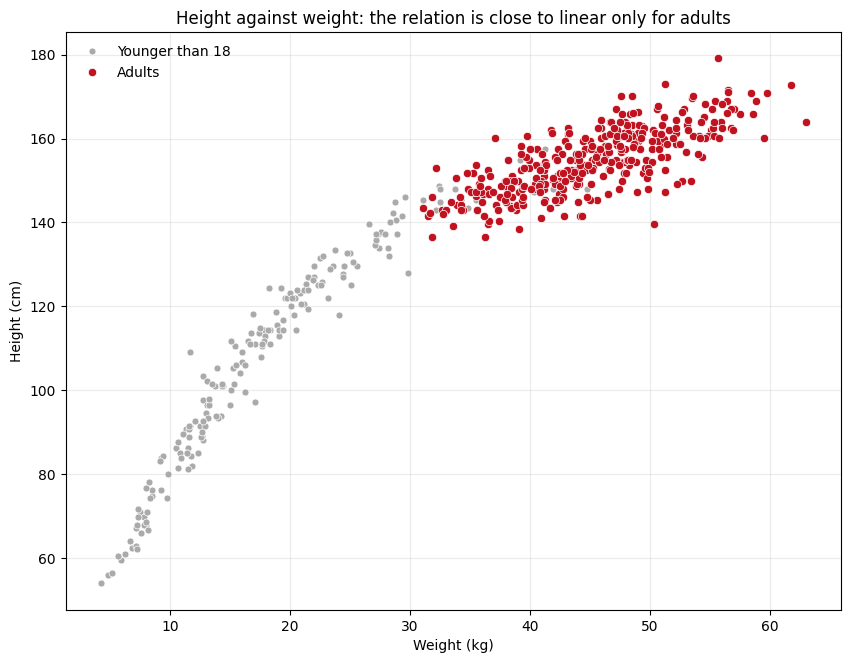

In [4]:
plt.figure(figsize=(10, 7.5))
plt.plot(children['weight'], children['height'], 'o', color='#aaaaaa', markersize=5, markeredgecolor='white',
         markeredgewidth=0.5, label='Younger than 18')
plt.plot(dat['weight'], dat['height'], 'o', color='#c1121f', markersize=6, markeredgecolor='white',
         markeredgewidth=0.5, label='Adults')

plt.xlabel('Weight (kg)')
plt.ylabel('Height (cm)')
plt.title('Height against weight: the relation is close to linear only for adults')
plt.legend(loc='best', frameon=False)
plt.grid(True, alpha=0.25)

## Computing the coefficients

For the line $y = \beta_0 + \beta_1 x$, the least squares estimators are
$$\hat\beta_1 = \frac{\sum_i (x_i-\bar x)(y_i-\bar y)}{\sum_i (x_i-\bar x)^2}, \qquad \hat\beta_0 = \bar y - \hat\beta_1\bar x.$$

In [5]:
x = dat['weight'].to_numpy()
Y = dat['height'].to_numpy()
n = len(dat)

num = sum((x-x.mean())*(Y-Y.mean()))
den = sum((x-x.mean())**2)

beta_1 = num/den
beta_0 = Y.mean() - beta_1*x.mean()

print('beta_0:', beta_0)
print('beta_1:', beta_1)

beta_0: 113.87939360689359
beta_1: 0.9050291086266465


The same with the least squares procedure

In [6]:
X = np.vstack([np.ones(n), x]).T
np.linalg.lstsq(X, Y, rcond=None)[0]

array([113.87939361,   0.90502911])

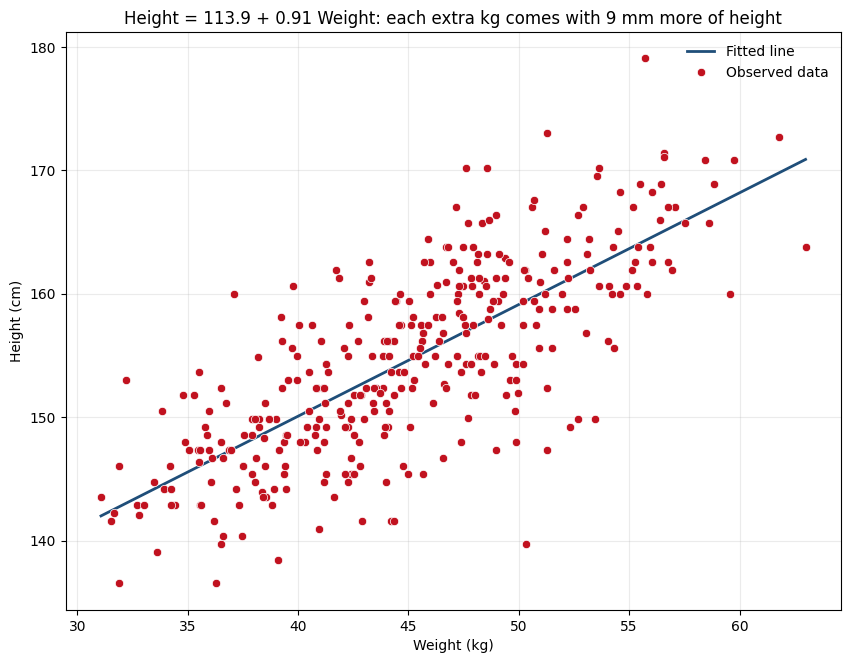

In [7]:
x_grid = np.array([x.min(), x.max()])

plt.figure(figsize=(10, 7.5))
plt.plot(x_grid, beta_0 + beta_1*x_grid, color='#1f4e79', lw=2, label='Fitted line')
plt.plot(x, Y, 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5,
         label='Observed data')

plt.xlabel('Weight (kg)')
plt.ylabel('Height (cm)')
plt.title(f'Height = {beta_0:.1f} + {beta_1:.2f} Weight: each extra kg comes with {10*beta_1:.0f} mm more of height')
plt.legend(loc='best', frameon=False)
plt.grid(True, alpha=0.25)

## What the line minimizes

The fitted line is the one with the smallest sum of squared vertical distances to the points (the residuals).

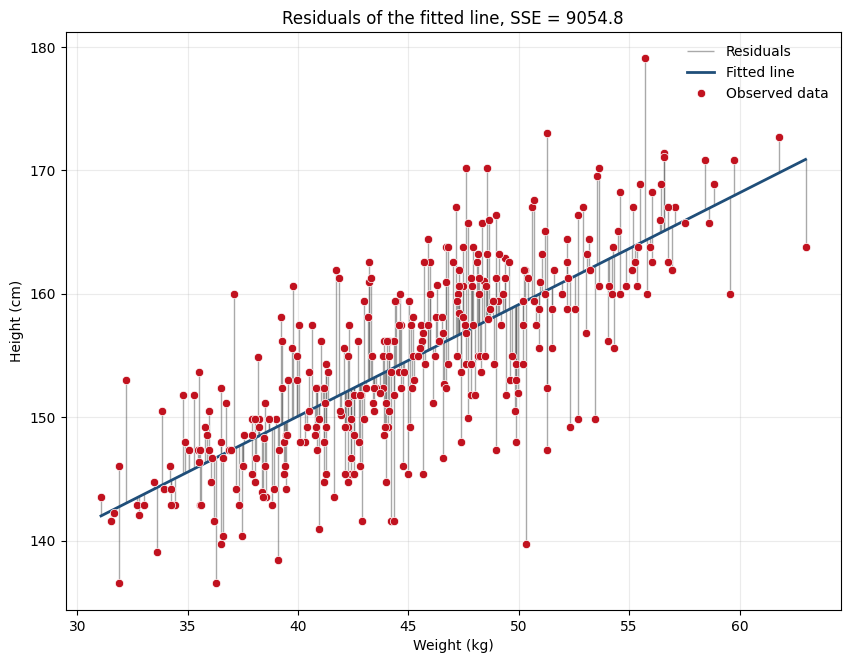

In [8]:
Y_hat = beta_0 + beta_1*x
SSE = sum((Y-Y_hat)**2)

plt.figure(figsize=(10, 7.5))
plt.vlines(x, Y_hat, Y, color='#555555', lw=1, alpha=0.5, label='Residuals')
plt.plot(x_grid, beta_0 + beta_1*x_grid, color='#1f4e79', lw=2, label='Fitted line')
plt.plot(x, Y, 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5,
         label='Observed data')

plt.xlabel('Weight (kg)')
plt.ylabel('Height (cm)')
plt.title(f'Residuals of the fitted line, SSE = {SSE:.1f}')
plt.legend(loc='best', frameon=False)
plt.grid(True, alpha=0.25)